# DATA 202 Final Project: Does Payroll Buy Wins?
## Notebook 05: Inside the Payroll

**Students:** Asher Ring & Elliot Asquith

**What this notebook does:** Looks at the player-level data to explain *why* payroll is a weak signal: how top-heavy salaries are, what different positions earn, and how much money went to players who were no longer on the team.

**Reads:** `data/mlb_player_salaries.csv`, `data/mlb_team_payroll_totals.csv`

**Creates:** `images/active_salary_distribution.png`

**Slides it supports:** A Few Stars Carry the Bill, Money Raises the Floor (\$841M figure)

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("data")
IMG_DIR = Path("images")
IMG_DIR.mkdir(exist_ok=True)

players = pd.read_csv(DATA_DIR / "mlb_player_salaries.csv")
teams = pd.read_csv(DATA_DIR / "mlb_team_payroll_totals.csv")

active = players[players["roster_group"] == "active"].copy()
salaries = active["payroll_salary"]          # full-season salary of each active-roster player
print("Active-roster players:", len(active))

Active-roster players: 834


### How top-heavy are salaries?

In [2]:
top_n = int(np.ceil(len(salaries) * 0.10))     # the top 10% of players
top_share = salaries.nlargest(top_n).sum() / salaries.sum()

print(f"Top 10% of active players ({top_n} players) earn {top_share:.0%} of active-roster salary")
print(f"Median active salary: ${salaries.median():,.0f}")
print(f"Mean active salary:   ${salaries.mean() / 1e6:.1f}M")

Top 10% of active players (84 players) earn 54% of active-roster salary
Median active salary: $810,000
Mean active salary:   $4.7M


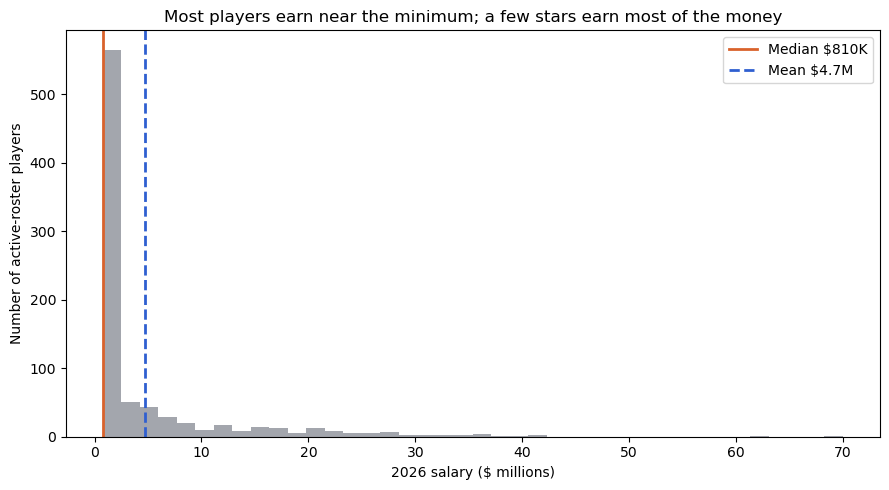

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(salaries / 1e6, bins=40, color="#A3A6AD")
ax.axvline(salaries.median() / 1e6, color="#D9622B", linewidth=2, label=f"Median ${salaries.median() / 1e3:,.0f}K")
ax.axvline(salaries.mean() / 1e6, color="#2F5FD0", linewidth=2, linestyle="--", label=f"Mean ${salaries.mean() / 1e6:.1f}M")
ax.set_title("Most players earn near the minimum; a few stars earn most of the money")
ax.set_xlabel("2026 salary ($ millions)")
ax.set_ylabel("Number of active-roster players")
ax.legend()
plt.tight_layout()
plt.savefig(IMG_DIR / "active_salary_distribution.png", dpi=200)
plt.show()

### What each position earns

Some players have two positions (for example `SP/DH`); we use the first one.

In [4]:
active["main_position"] = active["position"].str.split("/").str[0]
by_position = (active.groupby("main_position")["payroll_salary"]
               .agg(players="size", median_salary="median")
               .sort_values("players", ascending=False))
display(by_position)

for pos in ["SP", "RP", "C"]:
    print(f"{pos} median: ${by_position.loc[pos, 'median_salary'] / 1e6:.2f}M")

,players,median_salary
main_position,,
RP,255,796000.0
SP,157,2260000.0
C,74,863100.0
SS,67,810500.0
2B,49,811500.0
3B,45,804500.0
CF,42,805000.0
OF,41,780000.0
LF,36,2425000.0


SP median: $2.26M
RP median: $0.80M
C median: $0.86M


### Money paid to players who are no longer on the team

**Dead money** is pay owed to players a team released or traded. **Retained** salary is what a team kept paying after trading a player away. Neither buys a single win in 2026.

In [5]:
dead = teams["dead_money"].sum()
retained = teams["retained_payroll"].sum()
print(f"Dead money:      ${dead / 1e6:,.0f}M")
print(f"Retained salary: ${retained / 1e6:,.0f}M")
print(f"Total paid to players no longer on the roster: ${(dead + retained) / 1e6:,.0f}M")

Dead money:      $711M
Retained salary: $129M
Total paid to players no longer on the roster: $841M


### Row counts and biggest contract (slide footer)

In [6]:
print(players["roster_group"].value_counts().to_string())
top = players.loc[players["payroll_salary"].idxmax()]
print(f"\nTop contract: {top['player']}, ${top['payroll_salary'] / 1e6:.0f}M")

roster_group
active            834
dead              502
minor             398
injured           267
retained           21
suspended           6
personal_leave      3

Top contract: Shohei Ohtani, $70M


*What this shows:* the typical player earns close to the \$780K minimum while the top 10% take over half the money, so a team's payroll mostly reflects a handful of big contracts, some of them for players who are injured or gone.